# Hierarchical Model Comparison: Rescorla-Wagner (Valence) vs. Kalman Filter (Non-GAD)
This notebook fits and compares two alternative hierarchical cognitive models on the four-armed bandit task behavioral data:
1. **Rescorla-Wagner (Valence) Model:** Uses separate positive and negative learning rates ($\alpha_{pos}, \alpha_{neg}$) and choice stochasticity (inverse temperature $\beta$) for each subject.
2. **Kalman Filter (Non-GAD) Model:** Uses subject-level process noise $Q$ (drift variance), observation noise $R$ (measurement noise), and choice stochasticity $\beta$ (all log-normally distributed across subjects).

We draw posterior samples using the JAX-backed NUTS sampler (`numpyro`) and run Leave-One-Out cross-validation (LOO) via ArviZ to determine which model better explains the behavioral choices.


In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"

import pandas as pd
import numpy as np
import pymc as pm
import pytensor
import pytensor.tensor as pt
import matplotlib.pyplot as plt
import arviz as az
import xarray as xr
import warnings

# Import custom hierarchical learning functions
from learning_functions import update_m2_hierarchical

warnings.filterwarnings('ignore')


In [2]:
# Load Data
file_path = '../data/allsubs_combined.csv'
df = pd.read_csv(file_path)

# Filter out trials with missing choices
df = df.dropna(subset=['ChoiceKey']).copy()

# Map stimulus IDs
stim_map = {'W1': 0, 'W2': 1, 'L1': 2, 'L2': 3}
df['LeftID_int'] = df['LeftID'].map(stim_map)
df['RightID_int'] = df['RightID'].map(stim_map)
df['ChosenID_int'] = df['ChosenID'].map(stim_map)

# Map ChoiceKey
df['Choice'] = df['ChoiceKey'] - 1

# Scale rewards
df['RewardScaled'] = df['TrialPoints'] / 30.0

# Create SubIdx (0 to n_sub-1)
unique_subs = df['Sub'].unique()
sub_idx_map = {sub: i for i, sub in enumerate(unique_subs)}
df['SubIdx'] = df['Sub'].map(sub_idx_map)
n_sub = len(unique_subs)

# Mark the first trial of each subject
df['is_first'] = 0
for sub in unique_subs:
    sub_indices = df[df['Sub'] == sub].index
    if len(sub_indices) > 0:
        df.loc[sub_indices[0], 'is_first'] = 1

print(f"Total subjects: {n_sub}")
print(f"Total trials across all subjects: {len(df)}")


Total subjects: 67
Total trials across all subjects: 6520


In [3]:
def kalman_bandit_step(left_id, right_id, chosen_id, reward, is_first, sub_idx, 
                       mu_seq, sigma2_seq, Q_vector, R_vector):
    
    # 1. Time Update (Predict / Drift Step)
    mu_pred = pt.switch(is_first, 0.5, mu_seq[sub_idx])
    sigma2_pred = pt.switch(is_first, 1.0, sigma2_seq[sub_idx] + Q_vector[sub_idx])
    
    # Extract prediction elements for the chosen card
    mu_chosen = mu_pred[chosen_id]
    sigma2_chosen = sigma2_pred[chosen_id]
    
    # 2. Measurement Update (Correct / Learn Step)
    pe = reward - mu_chosen  # Prediction Error
    
    # Kalman Gain calculation: K = Sigma_pred / (Sigma_pred + R)
    K = sigma2_chosen / (sigma2_chosen + R_vector[sub_idx])
    
    # Update hidden state beliefs for the chosen card index
    mu_updated_chosen = mu_chosen + K * pe
    sigma2_updated_chosen = (1.0 - K) * sigma2_chosen
    
    # Reconstruct vectors (Only update chosen index, unchosen ones carry forward)
    mu_next = pt.set_subtensor(mu_pred[chosen_id], mu_updated_chosen)
    sigma2_next = pt.set_subtensor(sigma2_pred[chosen_id], sigma2_updated_chosen)
    
    # Store global state matrix update
    mu_new_matrix = pt.set_subtensor(mu_seq[sub_idx], mu_next)
    sigma2_new_matrix = pt.set_subtensor(sigma2_seq[sub_idx], sigma2_next)
    
    # Calculate action values for tracking choice likelihood
    q_left = mu_pred[left_id]
    q_right = mu_pred[right_id]
    
    return mu_new_matrix, sigma2_new_matrix, q_left, q_right


In [4]:
def make_hierarchical_alpha(name, n_sub):
    mu = pm.Normal(f'{name}_mu', mu=0, sigma=1.5)
    sigma = pm.HalfNormal(f'{name}_sigma', sigma=1.0)
    raw = pm.Normal(f'{name}_raw', mu=0, sigma=1, shape=n_sub)
    return pm.Deterministic(name, pm.math.invlogit(mu + raw * sigma))

def make_hierarchical_beta(name, n_sub):
    mu = pm.Normal(f'{name}_mu', mu=0, sigma=2.0)
    sigma = pm.HalfNormal(f'{name}_sigma', sigma=1.0)
    raw = pm.Normal(f'{name}_raw', mu=0, sigma=1, shape=n_sub)
    return pm.Deterministic(name, pm.math.exp(mu + raw * sigma))

def build_rw_valence_model(df, n_sub):
    with pm.Model() as rw_model:
        # Hierarchical parameters
        alpha_pos = make_hierarchical_alpha('alpha_pos', n_sub)
        alpha_neg = make_hierarchical_alpha('alpha_neg', n_sub)
        beta = make_hierarchical_beta('beta', n_sub)
        
        Q_init = pt.zeros((n_sub, 4))
        outputs_info = [Q_init, None, None, None]
        
        results, updates = pytensor.scan(
            fn=update_m2_hierarchical,
            sequences=[
                pt.as_tensor_variable(df['LeftID_int'].values),
                pt.as_tensor_variable(df['RightID_int'].values),
                pt.as_tensor_variable(df['ChosenID_int'].values),
                pt.as_tensor_variable(df['RewardScaled'].values),
                pt.as_tensor_variable(df['is_first'].values),
                pt.as_tensor_variable(df['SubIdx'].values)
            ],
            outputs_info=outputs_info,
            non_sequences=[alpha_pos, alpha_neg],
            strict=True
        )
        
        q_left_seq = results[1]
        q_right_seq = results[2]
        
        sub_idx_seq = pt.as_tensor_variable(df['SubIdx'].values)
        p_right_raw = pm.math.sigmoid(beta[sub_idx_seq] * (q_right_seq - q_left_seq))
        p_right = pm.Deterministic('p_right', pt.clip(p_right_raw, 1e-5, 1.0 - 1e-5))
        
        pm.Bernoulli('choice_obs', p=p_right, observed=df['Choice'].values)
        
    return rw_model

def build_kalman_model(df, n_sub):
    with pm.Model() as kf_model:
        # Hierarchical parameters
        # Process Noise Q (Drift variance)
        mu_Q_log = pm.Normal('mu_Q_log', mu=-2, sigma=1)
        sigma_Q = pm.HalfNormal('sigma_Q', sigma=1.0)
        Q_raw = pm.Normal('Q_raw', mu=0, sigma=1, shape=n_sub)
        Q_sub = pm.Deterministic('Q_sub', pm.math.exp(mu_Q_log + Q_raw * sigma_Q))
        
        # Observation Noise R (Measurement variance)
        mu_R_log = pm.Normal('mu_R_log', mu=-1, sigma=1)
        sigma_R = pm.HalfNormal('sigma_R', sigma=1.0)
        R_raw = pm.Normal('R_raw', mu=0, sigma=1, shape=n_sub)
        R_sub = pm.Deterministic('R_sub', pm.math.exp(mu_R_log + R_raw * sigma_R))
        
        # Inverse Temperature Beta
        mu_beta_log = pm.Normal('mu_beta_log', mu=1, sigma=1)
        sigma_beta = pm.HalfNormal('sigma_beta', sigma=0.5)
        beta_raw = pm.Normal('beta_raw', mu=0, sigma=1, shape=n_sub)
        beta = pm.Deterministic('beta', pm.math.exp(mu_beta_log + beta_raw * sigma_beta))
        
        # Hidden state initial configurations
        mu_init = pt.zeros((n_sub, 4)) + 0.5
        sigma2_init = pt.ones((n_sub, 4)) * 1.0
        
        # Sequential loops over trials using PyTensor Scan
        results, _ = pytensor.scan(
            fn=kalman_bandit_step,
            sequences=[
                pt.as_tensor_variable(df['LeftID_int'].values),
                pt.as_tensor_variable(df['RightID_int'].values),
                pt.as_tensor_variable(df['ChosenID_int'].values),
                pt.as_tensor_variable(df['RewardScaled'].values),
                pt.as_tensor_variable(df['is_first'].values),
                pt.as_tensor_variable(df['SubIdx'].values)
            ],
            outputs_info=[mu_init, sigma2_init, None, None],
            non_sequences=[Q_sub, R_sub],
            strict=True
        )
        
        q_left_seq = results[2]
        q_right_seq = results[3]
        
        # Softmax probabilistic choice link function
        sub_idx_seq = pt.as_tensor_variable(df['SubIdx'].values)
        p_right_raw = pm.math.sigmoid(beta[sub_idx_seq] * (q_right_seq - q_left_seq))
        p_right = pm.Deterministic('p_right', pt.clip(p_right_raw, 1e-5, 1.0 - 1e-5))
        
        pm.Bernoulli('choice_obs', p=p_right, observed=df['Choice'].values)
        
    return kf_model


In [5]:
print("--- Fit and Sample Rescorla-Wagner (Valence) Model ---")
m_rw = build_rw_valence_model(df, n_sub)
with m_rw:
    idata_rw = pm.sample(nuts_sampler="numpyro", draws=1000, tune=1000, chains=4, progressbar=True)
    p_rw = idata_rw.posterior["p_right"]
    y_xr = xr.DataArray(df["Choice"].values, dims=[p_rw.dims[-1]])
    idata_rw.add_groups(log_likelihood={"choice_obs": (np.log(p_rw) * y_xr + np.log(1.0 - p_rw) * (1.0 - y_xr)).transpose("chain", "draw", ...)})

print("\n--- Fit and Sample Kalman Filter (Non-GAD) Model ---")
m_kf = build_kalman_model(df, n_sub)
with m_kf:
    idata_kf = pm.sample(nuts_sampler="numpyro", draws=1000, tune=1000, chains=4, progressbar=True)
    p_kf = idata_kf.posterior["p_right"]
    y_xr = xr.DataArray(df["Choice"].values, dims=[p_kf.dims[-1]])
    idata_kf.add_groups(log_likelihood={"choice_obs": (np.log(p_kf) * y_xr + np.log(1.0 - p_kf) * (1.0 - y_xr)).transpose("chain", "draw", ...)})


--- Fit and Sample Rescorla-Wagner (Valence) Model ---


  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


... (3 outputs left out)

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


MODEL COMPARISON (LOO)
                           rank     elpd_loo       p_loo   elpd_diff  \
Rescorla-Wagner (Valence)     0 -2907.610973  150.830556    0.000000   
Kalman Filter (Non-GAD)       1 -3014.377747  143.280400  106.766774   

                             weight         se        dse  warning scale  
Rescorla-Wagner (Valence)  0.766831  44.049948   0.000000     True   log  
Kalman Filter (Non-GAD)    0.233169  41.639301  22.261422     True   log  



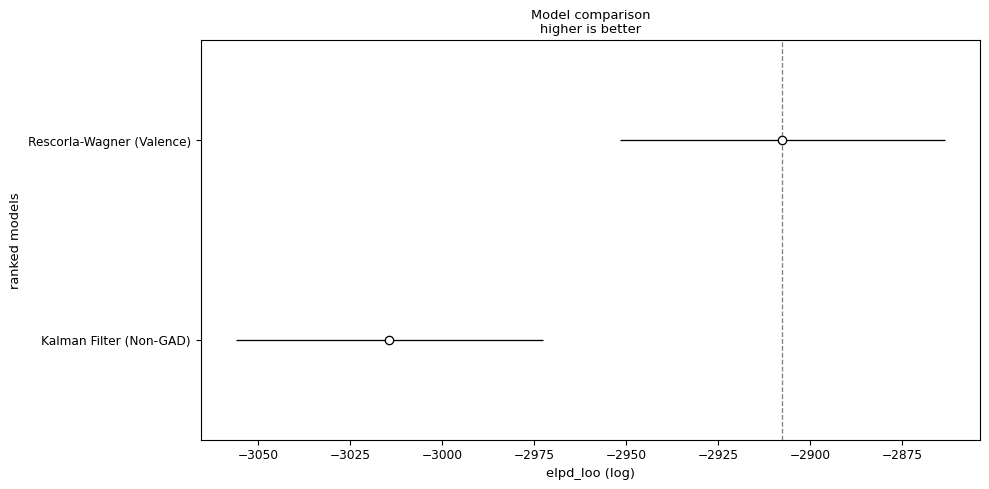

In [6]:
# Run ArviZ comparison
comp_dict = {
    "Rescorla-Wagner (Valence)": idata_rw,
    "Kalman Filter (Non-GAD)": idata_kf
}

comp = az.compare(comp_dict)
print("==================================================")
print("MODEL COMPARISON (LOO)")
print("==================================================")
print(comp)
print("==================================================\n")

# Plot the comparison results
fig, ax = plt.subplots(figsize=(10, 5))
az.plot_compare(comp, ax=ax, title=True)
plt.tight_layout()
plt.show()
